<a href="https://colab.research.google.com/github/tanishgupta1211/college-complaint-classification/blob/main/notebooks/01_project_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# College Complaint Classification System

## Project Overview

This project aims to automatically classify college student complaints into relevant categories using Natural Language Processing (NLP) and Machine Learning.

## Objectives
- Collect and analyze a suitable complaint dataset.
- Preprocess English and Hindi/Hinglish complaint text.
- Convert text into numerical features using TF-IDF.
- Train and compare machine learning classification models.
- Evaluate model performance using accuracy, precision, recall, and F1-score.
- Predict the category of a new complaint.

## Tools and Technologies
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- GitHub

## Project Workflow
1. Dataset collection
2. Data exploration and cleaning
3. Text preprocessing
4. Feature extraction
5. Model training
6. Model evaluation
7. Complaint prediction

**Project Status:** Day 1 — Project Setup

In [8]:

# Import the libraries we need

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset


In [9]:

# Load the college complaint data

dataset = load_dataset("alaminxpro/university-students-complaints")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))


README.md:   0%|          | 0.00/7.44k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/61.8k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/13.7k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/273 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/59 [00:00<?, ? examples/s]

Training rows: 273
Testing rows: 59


In [10]:

# Count complaints in each category

category_counts = train_df["Category"].value_counts()
print(category_counts)


Category
Infrastructure    114
Technical          58
Academic           48
Finance            29
Administrative     24
Name: count, dtype: int64


In [11]:

# Check for missing and duplicate data

print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

print(
    "Empty complaints:",
    train_df["Complaint_Description"].fillna("").str.strip().eq("").sum()
)


Missing values:
ID                         0
Timestamp                  0
Gender                     0
Semester                   0
Student_Dept               0
Complaint_Description      0
Category                   0
Responsible_Departments    0
Primary_Department         0
Aspects                    0
Severity                   0
Complaint_Group_ID         0
dtype: int64

Duplicate rows: 0
Empty complaints: 0


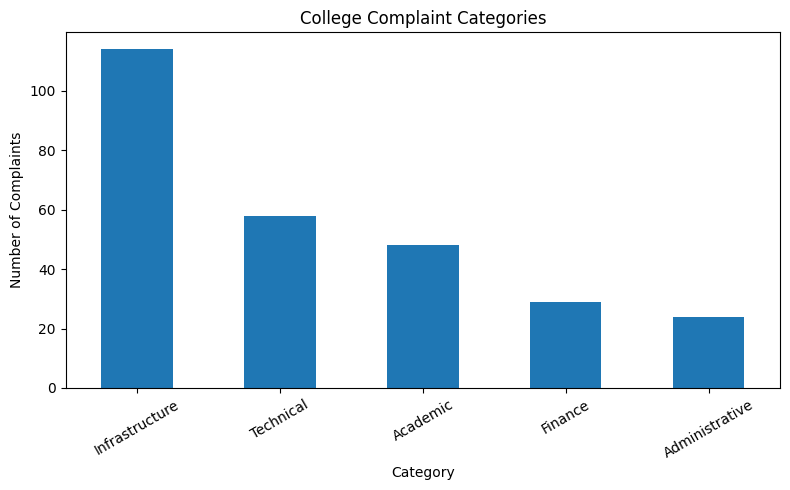

In [12]:

# Plot the complaint categories

category_counts.plot(kind="bar", figsize=(8, 5))

plt.title("College Complaint Categories")
plt.xlabel("Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [13]:

print(train_df.shape)
print(test_df.shape)


(273, 12)
(59, 12)


In [14]:
train_df["Complaint_Group_ID"].value_counts().head(10)

,count
Complaint_Group_ID,
20,8
11,4
4,4
8,4
23,4
21,4
19,4
12,4
3,4


In [15]:

train_groups = set(train_df["Complaint_Group_ID"])
test_groups = set(test_df["Complaint_Group_ID"])

common_groups = train_groups.intersection(test_groups)

print("Unique groups in training:", len(train_groups))
print("Unique groups in testing:", len(test_groups))
print("Groups present in both:", len(common_groups))


Unique groups in training: 153
Unique groups in testing: 33
Groups present in both: 0


In [16]:

# Check complaints from group 20

group_data = train_df[train_df["Complaint_Group_ID"] == 20]

display(group_data[["Complaint_Description", "Category"]])


,Complaint_Description,Category
14,We need more research facilities in our univer...,Academic
16,We need more research facilities in our univer...,Academic
64,We would benefit from more research facilities...,Academic
67,We require more research facilities in our uni...,Academic
119,We are in need of more research facilities in ...,Academic
121,We would benefit from more research facilities...,Academic
170,We require more research facilities in our uni...,Academic
171,We are in need of more research facilities in ...,Academic


In [17]:

# Check complaints from group 20

group_data = train_df[train_df["Complaint_Group_ID"] == 20]

display(group_data[["Complaint_Description", "Category"]])


,Complaint_Description,Category
14,We need more research facilities in our univer...,Academic
16,We need more research facilities in our univer...,Academic
64,We would benefit from more research facilities...,Academic
67,We require more research facilities in our uni...,Academic
119,We are in need of more research facilities in ...,Academic
121,We would benefit from more research facilities...,Academic
170,We require more research facilities in our uni...,Academic
171,We are in need of more research facilities in ...,Academic


In [18]:

# Count complaints in each group

group_counts = train_df["Complaint_Group_ID"].value_counts()

print("Total groups:", len(group_counts))
print("Groups with multiple complaints:", (group_counts > 1).sum())
print("Largest group size:", group_counts.max())


Total groups: 153
Groups with multiple complaints: 46
Largest group size: 8


In [19]:

# Check categories within each group

cat_per_group = train_df.groupby("Complaint_Group_ID")["Category"].nunique()

print("Groups with different categories:", (cat_per_group > 1).sum())
print("Groups with one category:", (cat_per_group == 1).sum())


Groups with different categories: 0
Groups with one category: 153


In [20]:

# Check categories in test groups

test_cats = test_df.groupby("Complaint_Group_ID")["Category"].nunique()

print("Test groups with different categories:", (test_cats > 1).sum())
print("Test groups with one category:", (test_cats == 1).sum())


Test groups with different categories: 0
Test groups with one category: 33


## Day 2: Complaint Group Analysis

### Objective
Understand complaint groups and check whether related complaints are separated between training and testing data.

### Work Completed
- Checked complaint counts for each `Complaint_Group_ID`.
- Inspected complaints from Group 20.
- Checked category consistency within training and testing groups.
- Checked for common group IDs between training and testing data.

### Findings
- Training data contains 153 unique groups.
- Testing data contains 33 unique groups.
- 46 training groups contain multiple complaints.
- The largest training group contains 8 complaints.
- All 153 training groups have consistent categories.
- All 33 testing groups have consistent categories.
- No group IDs are shared between training and testing data.

### Conclusion
The group IDs are useful for analysing related complaints. No group overlap was found between the training and testing sets, which reduces the risk of leakage through shared groups.

### Next Step
Prepare complaint text for machine learning and explore text preprocessing techniques.

In [21]:
# Look at a few complaint examples

train_df["Complaint_Description"].head()

,Complaint_Description
0,"On most parts of the 8th/9th floor, WiFi is no..."
1,need a seperate female prayer room which is no...
2,drinking water system on the 6th floor(CSE dpt...
3,Some projectors are not clear
4,Campus WiFi does not work in all areas and is ...


In [22]:
# Check one complaint in its original form

text = train_df["Complaint_Description"].iloc[0]

print("Original complaint:")
print(text)

print("\nLowercase version:")
print(text.lower())

Original complaint:
On most parts of the 8th/9th floor, WiFi is not available at all.

Lowercase version:
on most parts of the 8th/9th floor, wifi is not available at all.


In [23]:
# Convert all complaint text to lowercase

train_df["clean_text"] = train_df["Complaint_Description"].str.lower()

train_df[["Complaint_Description", "clean_text"]].head()

,Complaint_Description,clean_text
0,"On most parts of the 8th/9th floor, WiFi is no...","on most parts of the 8th/9th floor, wifi is no..."
1,need a seperate female prayer room which is no...,need a seperate female prayer room which is no...
2,drinking water system on the 6th floor(CSE dpt...,drinking water system on the 6th floor(cse dpt...
3,Some projectors are not clear,some projectors are not clear
4,Campus WiFi does not work in all areas and is ...,campus wifi does not work in all areas and is ...


In [24]:
# Compare text before and after lowercase conversion

print("Original:")
print(train_df["Complaint_Description"].iloc[0])

print("\nCleaned:")
print(train_df["clean_text"].iloc[0])

print("\nTotal complaints:", len(train_df["clean_text"]))


Original:
On most parts of the 8th/9th floor, WiFi is not available at all.

Cleaned:
on most parts of the 8th/9th floor, wifi is not available at all.

Total complaints: 273


In [25]:
# Compare the length of original and cleaned text

train_df["original_len"] = train_df["Complaint_Description"].str.len()
train_df["clean_len"] = train_df["clean_text"].str.len()

print("Original text length:")
print(train_df["original_len"].describe())

print("\nCleaned text length:")
print(train_df["clean_len"].describe())

Original text length:
count    273.000000
mean     110.699634
std       89.840246
min       24.000000
25%       52.000000
50%       88.000000
75%      133.000000
max      520.000000
Name: original_len, dtype: float64

Cleaned text length:
count    273.000000
mean     110.699634
std       89.840246
min       24.000000
25%       52.000000
50%       88.000000
75%      133.000000
max      520.000000
Name: clean_len, dtype: float64


In [26]:
# Check for missing or blank complaint text

missing = train_df["clean_text"].isna().sum()
blank = train_df["clean_text"].fillna("").str.strip().eq("").sum()

print("Missing complaints:", missing)
print("Blank complaints:", blank)

Missing complaints: 0
Blank complaints: 0


In [27]:
# Import TF-IDF for converting text into numbers

from sklearn.feature_extraction.text import TfidfVectorizer

In [28]:
# Create the TF-IDF vectorizer

tfidf = TfidfVectorizer(max_features=1000)

print(tfidf)

TfidfVectorizer(max_features=1000)


In [29]:
# Convert training complaints into numerical features

x_train = tfidf.fit_transform(train_df["clean_text"])

print("Shape:", x_train.shape)
print("Data type:", type(x_train))

Shape: (273, 645)
Data type: <class 'scipy.sparse._csr.csr_matrix'>


In [30]:
# View the words and their TF-IDF values

words = tfidf.get_feature_names_out()
values = x_train[0].toarray()[0]

word_data = pd.DataFrame({
    "word": words,
    "tfidf": values
})

word_data = word_data[word_data["tfidf"] > 0]
word_data = word_data.sort_values("tfidf", ascending=False)

display(word_data.head(10))

,word,tfidf
8,9th,0.356759
58,available,0.356759
404,parts,0.356759
7,8th,0.309448
355,most,0.301409
25,all,0.301409
634,wifi,0.257999
229,floor,0.250407
381,on,0.243576
52,at,0.234462


In [31]:
# Convert test complaints using the same TF-IDF vocabulary

test_df["clean_text"] = test_df["Complaint_Description"].str.lower()

x_test = tfidf.transform(test_df["clean_text"])

y_train = train_df["Category"]
y_test = test_df["Category"]

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (273, 645)
Testing features: (59, 645)
Training labels: (273,)
Testing labels: (59,)


In [32]:
# Import the classification model

from sklearn.linear_model import LogisticRegression

In [33]:
# Create and train the model

model = LogisticRegression(max_iter=1000)

model.fit(x_train, y_train)

print("Model training complete!")

Model training complete!


In [35]:
# Predict categories for unseen complaints

y_pred = model.predict(x_test)

print("Actual categories:")
print(y_test.head(10).to_list())

print("\nPredicted categories:")
print(y_pred[:10])

Actual categories:
['Infrastructure', 'Technical', 'Academic', 'Infrastructure', 'Infrastructure', 'Administrative', 'Technical', 'Infrastructure', 'Infrastructure', 'Academic']

Predicted categories:
['Infrastructure' 'Infrastructure' 'Infrastructure' 'Infrastructure'
 'Infrastructure' 'Infrastructure' 'Infrastructure' 'Infrastructure'
 'Infrastructure' 'Infrastructure']


In [36]:
# Check how many test predictions are correct

from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_pred)

print("Test accuracy:", round(acc * 100, 2), "%")

Test accuracy: 55.93 %


In [37]:
# Evaluate performance for each complaint category

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

                precision    recall  f1-score   support

      Academic       1.00      0.06      0.12        16
Administrative       0.00      0.00      0.00         3
       Finance       1.00      0.50      0.67         4
Infrastructure       0.56      1.00      0.72        29
     Technical       0.25      0.14      0.18         7

      accuracy                           0.56        59
     macro avg       0.56      0.34      0.34        59
  weighted avg       0.64      0.56      0.45        59



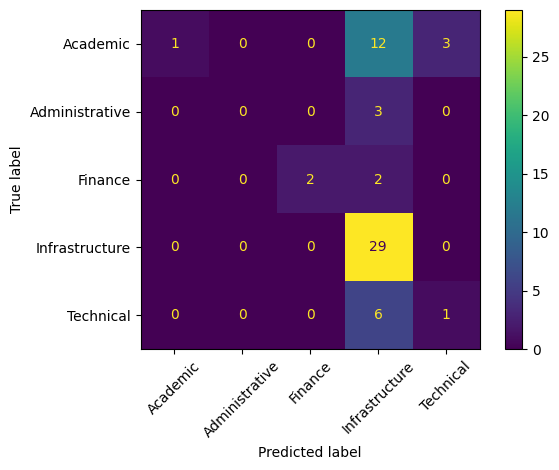

In [38]:
# See which categories the model confuses

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [39]:
# Train a model that gives more weight to smaller classes

balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(x_train, y_train)

balanced_pred = balanced_model.predict(x_test)

print(classification_report(
    y_test,
    balanced_pred,
    zero_division=0
))

                precision    recall  f1-score   support

      Academic       1.00      0.56      0.72        16
Administrative       0.75      1.00      0.86         3
       Finance       0.50      1.00      0.67         4
Infrastructure       0.87      0.93      0.90        29
     Technical       0.43      0.43      0.43         7

      accuracy                           0.78        59
     macro avg       0.71      0.78      0.71        59
  weighted avg       0.82      0.78      0.78        59



In [40]:
# Compare both models on the same test data

from sklearn.metrics import accuracy_score, f1_score

print("Baseline accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Balanced accuracy:",
      round(accuracy_score(y_test, balanced_pred), 4))

print("Baseline macro F1:",
      round(f1_score(y_test, y_pred, average="macro"), 4))

print("Balanced macro F1:",
      round(f1_score(y_test, balanced_pred, average="macro"), 4))

Baseline accuracy: 0.5593
Balanced accuracy: 0.7797
Baseline macro F1: 0.3364
Balanced macro F1: 0.7145


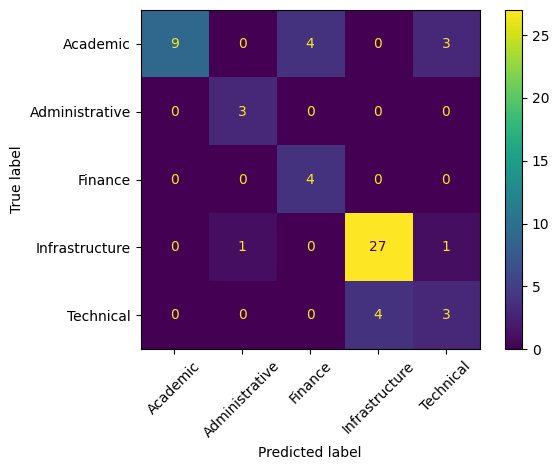

In [41]:
# Check errors made by the balanced model

cm_bal = confusion_matrix(
    y_test,
    balanced_pred,
    labels=balanced_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bal,
    display_labels=balanced_model.classes_
)

disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

## Day 3: Text Preprocessing

### Objective
Understand the complaint text and prepare it for machine learning.

### Work Completed
- Inspected sample complaints from the training dataset.
- Converted complaint text to lowercase.
- Created a new `clean_text` column while preserving the original complaint descriptions.
- Compared original and cleaned text lengths.
- Checked for missing and blank complaint descriptions.

### Code Summary
```python
train_df["clean_text"] = train_df["Complaint_Description"].str.lower()
```

### Findings
- The training dataset contains 273 complaints.
- Average complaint length is approximately 111 characters.
- Median complaint length is 88 characters.
- The shortest complaint contains 24 characters.
- The longest complaint contains 520 characters.
- No missing or blank complaints were found in the training text.
- Lowercase conversion did not change the length of the complaints.

### Key Learnings
- Text preprocessing helps maintain consistency in complaint text.
- The original text should be preserved for comparison and analysis.
- Aggressive cleaning is not always necessary because punctuation and numbers may provide useful context.
- Common words will be handled through TF-IDF rather than being removed blindly.

### Conclusion
Basic text preprocessing was completed successfully. The training complaints are ready for TF-IDF feature extraction.

### Next Step
Convert complaint text into numerical features using TF-IDF.


## Day 4: TF-IDF and Initial Model Training

### Objective
Convert complaint text into numerical features, train a classification model, and evaluate its performance.

### Work Completed
- Imported `TfidfVectorizer` from scikit-learn.
- Created a TF-IDF vectorizer with a maximum of 1,000 features.
- Converted training complaints into numerical features.
- Converted test complaints using the same fitted vectorizer.
- Separated text features (`X`) and category labels (`y`).
- Trained a Logistic Regression baseline model.
- Evaluated predictions using accuracy, classification report, and confusion matrix.
- Trained a second model using balanced class weights.
- Compared the performance of both models.

### TF-IDF Feature Extraction
```python
tfidf = TfidfVectorizer(max_features=1000)

x_train = tfidf.fit_transform(train_df["clean_text"])
x_test = tfidf.transform(test_df["clean_text"])
```

The vectorizer generated 645 features from the training text. TF-IDF assigns numerical weights to words based on their importance within a document and the overall training corpus.

The test data was transformed using the training vocabulary to avoid information leakage.

### Models Trained
1. **Baseline model:** Logistic Regression with default class weighting.
2. **Balanced model:** Logistic Regression using `class_weight="balanced"`.

### Evaluation Results

| Metric | Baseline | Balanced |
|---|---:|---:|
| Test accuracy | 55.93% | 77.97% |
| Macro F1-score | 0.3364 | 0.7145 |

### Key Findings
- The baseline model tended to predict Infrastructure for many complaints.
- The balanced model improved recognition of less represented categories.
- Academic and Technical complaints remain challenging.
- Administrative and Finance results were strong, but their test samples were small.
- The balanced model performed better on this test set and is the stronger candidate so far.

### Limitations
- The dataset contains a relatively small number of labeled complaints.
- The test set contains only 59 complaints.
- Performance on English complaints does not establish performance on Hindi or Hinglish complaints.
- Further validation is required before selecting the final model.

### Conclusion
TF-IDF and Logistic Regression successfully established a baseline classification system. Applying balanced class weights improved test accuracy and macro F1-score.

### Next Step
Compare model settings using training data and validation, analyse remaining classification errors, and carefully evaluate the selected model.
